# **Marginal Split Conformal Prediction**

Now we shall apply marginal split conformal prediction to the frozen models.

In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import pandas as pd
import sklearn

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

random_state = 42
alpha = 0.10

EXPECTED_LABELLED_PLANETS = 41423
EXPECTED_SPECTRAL_CHANNELS = 52
EXPECTED_FEATURE_COUNT = 111

EXPECTED_SPLIT_COUNTS = {
    "train": 24853,
    "validation": 4142,
    "calibration": 6214,
    "test": 6214
}

SPECTRUM_FEATURES = [f"spectrum_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)]

NOISE_FEATURES = [f"noise_{channel:02d}" for channel in range(EXPECTED_SPECTRAL_CHANNELS)]

METADATA_FEATURES = [
    "star_distance",
    "star_mass_kg",
    "star_radius_m",
    "star_temperature",
    "planet_mass_kg",
    "planet_orbital_period",
    "planet_distance"
]

TARGET_COLUMNS = [
    "planet_radius",
    "planet_temp",
    "log_H2O",
    "log_CO2",
    "log_CO",
    "log_CH4",
    "log_NH3"
]

FEATURE_COLUMNS = (SPECTRUM_FEATURES + NOISE_FEATURES + METADATA_FEATURES)

print("Frozen feature count:", len(FEATURE_COLUMNS))
print("Target count:", len(TARGET_COLUMNS))

Frozen feature count: 111
Target count: 7


In [3]:
TRAINING_DIRECTORY = PROJECT_ROOT / "FullDataset" / "TrainingData"
SPECTRAL_PATH = TRAINING_DIRECTORY / "SpectralData.hdf5"
AUXILIARY_PATH = TRAINING_DIRECTORY / "AuxillaryTable.csv"
TARGET_PATH = TRAINING_DIRECTORY / "Ground Truth Package" / "FM_Parameter_Table.csv"

SPLIT_ASSIGNMENT_PATH = PROJECT_ROOT / "data" / "processed" / "split_assignments_data.csv"
CHECKPOINT_DIRECTORY = PROJECT_ROOT / "checkpoints" / "predictive_baselines"

required_paths = [
    SPECTRAL_PATH,
    AUXILIARY_PATH,
    TARGET_PATH,
    SPLIT_ASSIGNMENT_PATH,
    CHECKPOINT_DIRECTORY
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

print("Source data, split assignments and checkpoints found.")

Source data, split assignments and checkpoints found.


###  **1. Load the calibration and test data**

In [4]:
split_assignment = pd.read_csv(SPLIT_ASSIGNMENT_PATH, dtype={"planet_ID": "string",
                                                            "split": "string"})

split_assignment = split_assignment[["planet_ID", "split"]].sort_values("planet_ID", kind="stable").reset_index(drop=True)
display(split_assignment)

,planet_ID,split
0,train1,calibration
1,train10,validation
2,train100,train
3,train1000,train
4,train10000,test
...,...,...
41418,train9995,train
41419,train9996,train
41420,train9997,train
41421,train9998,test


In [5]:
split_summary = split_assignment["split"].value_counts().reindex(["train", "validation", "calibration", "test"]
                                                                    ).rename_axis("split").to_frame("n_planets")
split_summary["fraction"] = split_summary["n_planets"] / len(split_assignment)
display(split_summary)

,n_planets,fraction
split,,
train,24853,0.599981
validation,4142,0.099993
calibration,6214,0.150013
test,6214,0.150013


In [6]:
metadata_source = pd.read_csv(AUXILIARY_PATH, dtype={"planet_ID": "string"})
target_source = pd.read_csv(TARGET_PATH, dtype={"planet_ID": "string"})
labelled_table = metadata_source[["planet_ID", *METADATA_FEATURES]].merge(
                                                                target_source[["planet_ID", *TARGET_COLUMNS]],
                                                                on="planet_ID",
                                                                how="inner",
                                                                validate="one_to_one")

labelled_by_id = labelled_table.set_index("planet_ID")
ids_calibration = split_assignment.loc[split_assignment["split"].eq("calibration"),"planet_ID"].tolist()

# Calling this 'internal' test here as to differentiate between our test split
# and the final ARIEL challenge test set.
ids_internal_test = split_assignment.loc[split_assignment["split"].eq("test"),"planet_ID"].tolist()

print("Calibration IDs:", len(ids_calibration))
print("Internal test IDs:", len(ids_internal_test))

Calibration IDs: 6214
Internal test IDs: 6214


We carry out the above check to make sure metadata target values aren't accidentally combined due to them occupying the same row positions.

In [7]:
display(labelled_by_id)

,star_distance,star_mass_kg,star_radius_m,star_temperature,planet_mass_kg,planet_orbital_period,planet_distance,planet_radius,planet_temp,log_H2O,log_CO2,log_CO,log_CH4,log_NH3
planet_ID,,,,,,,,,,,,,,
train1,530.7650,1.968526e+30,6.678720e+08,5636.0,3.990923e+26,9.668577,0.088530,0.559620,863.394770,-8.865868,-6.700707,-5.557561,-8.957615,-3.097540
train2,440.0890,1.948642e+30,7.235280e+08,5449.0,4.977001e+26,4.218028,0.050752,1.118308,1201.700465,-4.510258,-8.228966,-3.565427,-7.807424,-3.633658
train3,1126.3700,2.147483e+30,7.791840e+08,5675.0,9.686804e+25,2.828042,0.040158,0.400881,1556.096477,-7.225472,-6.931472,-3.081975,-8.567854,-5.378472
train4,1257.1600,2.048062e+30,7.374420e+08,5849.0,4.486340e+25,3.855604,0.048601,0.345974,1268.624884,-7.461157,-5.853334,-3.044711,-5.149378,-3.815568
train5,211.5530,2.525281e+30,1.092249e+09,6200.0,2.416329e+26,3.076340,0.044833,0.733184,1707.323564,-4.140844,-7.460278,-3.181793,-5.996593,-4.535345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
train41419,703.3020,1.988410e+30,7.722270e+08,5821.0,7.125924e+26,5.370647,0.060024,1.430950,1167.563319,-7.556565,-7.075889,-4.735715,-7.532563,-7.854443
train41420,72.7998,1.292466e+30,4.035060e+08,4258.0,7.709155e+25,6.342000,0.058089,0.277752,649.703932,-7.434332,-7.161510,-5.274940,-4.100312,-3.651804
train41421,1786.4800,1.789569e+30,7.096140e+08,6002.0,2.794853e+25,3.546511,0.043946,0.136016,1445.371723,-5.525906,-5.079240,-4.945121,-5.787630,-8.015444


In [8]:
"""
Build one feature matrix and target matrix via the ID ordering.
"""
def build_split(planet_ids, spectral_file):
    spectrum_values = np.stack([
        spectral_file[f"Planet_{planet_id}"]
        ["instrument_spectrum"][()]
        for planet_id in planet_ids
    ])

    noise_values = np.stack([
        spectral_file[f"Planet_{planet_id}"]
        ["instrument_noise"][()]
        for planet_id in planet_ids
    ])

    metadata_values = labelled_by_id.loc[planet_ids, METADATA_FEATURES].to_numpy()

    X = pd.DataFrame(np.column_stack([
        spectrum_values, noise_values,
        metadata_values]),
        index=pd.Index(planet_ids, name="planet_ID"),columns = FEATURE_COLUMNS)

    y = labelled_by_id.loc[planet_ids, TARGET_COLUMNS].copy()

    return X, y


In [9]:
with h5py.File(SPECTRAL_PATH, "r") as spectral_file:
    X_calib, y_calib = build_split(ids_calibration, spectral_file)

    X_internal_test, y_internal_test = build_split(ids_internal_test, spectral_file)

In [10]:
partition_objects = {
    "calibration": (X_calib, y_calib),
    "internal_test": (X_internal_test, y_internal_test)
}

partition_summary_rows = []

for partition_name, (X, y) in partition_objects.items():
    if X.shape != (6214 , EXPECTED_FEATURE_COUNT):
            raise ValueError(f"{partition_name} feature shape not as expected: {X.shape}")

    if y.shape != (6214 , len(TARGET_COLUMNS)):
            raise ValueError(f"{partition_name} target shape not as expected: {y.shape}")

    partition_summary_rows.append({
           "partition": partition_name,
           "n_planets": len(X),
           "n_features": X.shape[1],
           "n_targets": y.shape[1],
           "first_planet_ID": X.index[0],
           "last_planet_ID": X.index[-1]
    })

partition_summary = pd.DataFrame(partition_summary_rows).set_index("partition")
display(partition_summary)

,n_planets,n_features,n_targets,first_planet_ID,last_planet_ID
partition,,,,,
calibration,6214,111,7,train1,train999
internal_test,6214,111,7,train10000,train9998


We will now load the saved prediction models for each target.

In [11]:
import torch
from torch import nn
from joblib import load

device = torch.device("cpu")

nn_targets = [
    "planet_radius",
    "log_H2O",
    "log_CO2",
    "log_CH4",
    "log_NH3"
]

hgb_targets = [
    "planet_temp",
    "log_CO"
]

In [12]:
class NNRegression(nn.Module):
    def __init__(self, n_features, hidden_layers):
        super().__init__()

        layers = []
        input_width = n_features

        for hidden_width in hidden_layers:
            layers.append(nn.Linear(input_width, hidden_width))
            layers.append(nn.ReLU())
            input_width = hidden_width

        layers.append(nn.Linear(input_width, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)


In [13]:
nn_models = {}
nn_checkpoints = {}

for target in nn_targets:
    checkpoint_path = CHECKPOINT_DIRECTORY / f"{target}_selected_nn.pt"
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

    assert checkpoint["target"] == target
    assert checkpoint["feature_columns"] == FEATURE_COLUMNS

    hidden_layers = tuple(checkpoint["configuration"]["hidden_layers"])
    model = NNRegression(n_features=len(FEATURE_COLUMNS),
                         hidden_layers=hidden_layers)
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()

    nn_models[target] = model
    nn_checkpoints[target] = checkpoint
    print(f"Loaded NN for {target}: {checkpoint['configuration']['architecture']}")

Loaded NN for planet_radius: 111-128-64-1
Loaded NN for log_H2O: 111-128-64-1
Loaded NN for log_CO2: 111-64-1
Loaded NN for log_CH4: 111-128-64-1
Loaded NN for log_NH3: 111-128-64-1


In [14]:
hgb_models = {}

for target in hgb_targets:
    checkpoint_path = CHECKPOINT_DIRECTORY / f"{target}_selected_hgb.joblib"
    model = load(checkpoint_path)

    assert model.n_features_in_ == len(FEATURE_COLUMNS)
    assert model.feature_names_in_.tolist() == FEATURE_COLUMNS
    hgb_models[target] = model
    print(f"Loaded HGB model for {target}")

Loaded HGB model for planet_temp
Loaded HGB model for log_CO


## **2. Create calibration and test predictions**

For the NNs, we use standardisation of the mean of the feature and scale from the saved checkpoints.

The output of the NN is standardised initially and then converted back to the original scale using the target mean and scale.

The HGB models do not undergo any scaling.

In [15]:
def predict_nn(model, checkpoint, X):
    feature_mean = checkpoint["feature_scaler_mean"].cpu().numpy()
    feature_scale = checkpoint["feature_scaler_scale"].cpu().numpy()

    X_scaled = (X.to_numpy(dtype=np.float64) - feature_mean) / feature_scale
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32, device=device)

    with torch.no_grad():
        scaled_pred = model(X_tensor).squeeze(1).cpu().numpy()

    target_mean = checkpoint["target_scaler_mean"].cpu().numpy().item()
    target_scale = checkpoint["target_scaler_scale"].cpu().numpy().item()

    prediction = scaled_pred * target_scale + target_mean
    return prediction

In [16]:
calib_pred_columns = {}
test_pred_columns = {}

for target in TARGET_COLUMNS:
    if target in nn_targets:
        calib_pred = predict_nn(nn_models[target], nn_checkpoints[target], X_calib)
        test_pred = predict_nn(nn_models[target], nn_checkpoints[target], X_internal_test)
        model_family = "PyTorch NN"

    else:
        calib_pred = hgb_models[target].predict(X_calib)
        test_pred = hgb_models[target].predict(X_internal_test)
        model_family = "HGB"

    calib_pred_columns[target] = calib_pred
    test_pred_columns[target] = test_pred

    print(f"{target}: {model_family} ----- calibration predictions = {calib_pred.shape} ---- test predictions = {test_pred.shape}")

planet_radius: PyTorch NN ----- calibration predictions = (6214,) ---- test predictions = (6214,)
planet_temp: HGB ----- calibration predictions = (6214,) ---- test predictions = (6214,)
log_H2O: PyTorch NN ----- calibration predictions = (6214,) ---- test predictions = (6214,)
log_CO2: PyTorch NN ----- calibration predictions = (6214,) ---- test predictions = (6214,)
log_CO: HGB ----- calibration predictions = (6214,) ---- test predictions = (6214,)
log_CH4: PyTorch NN ----- calibration predictions = (6214,) ---- test predictions = (6214,)
log_NH3: PyTorch NN ----- calibration predictions = (6214,) ---- test predictions = (6214,)


In [17]:
calib_predictions = pd.DataFrame(calib_pred_columns, index=X_calib.index)[TARGET_COLUMNS]
test_predictions = pd.DataFrame(test_pred_columns, index=X_internal_test.index)[TARGET_COLUMNS]
print("Calibration prediction shape: ",  calib_predictions.shape)
print("Test prediction shape: ", test_predictions.shape)


Calibration prediction shape:  (6214, 7)
Test prediction shape:  (6214, 7)


In [18]:
display(pd.DataFrame({"target": TARGET_COLUMNS, "model_family":
                     [
                        ("PyTorch NN" if target in nn_targets else "HGB")
                         for target in TARGET_COLUMNS]
                         }
                        )
                    )

,target,model_family
0,planet_radius,PyTorch NN
1,planet_temp,HGB
2,log_H2O,PyTorch NN
3,log_CO2,PyTorch NN
4,log_CO,HGB
5,log_CH4,PyTorch NN
6,log_NH3,PyTorch NN


## **3. Calculate conformity scores**

For each target the conformity score is determined as:
$$s_i = \left|y_i - \hat{f}(x_i)\right|.$$

In [19]:
calib_residuals = y_calib[TARGET_COLUMNS] - calib_predictions[TARGET_COLUMNS]
calib_scores = calib_residuals.abs()
calibration_score_summary = pd.DataFrame({
    "mean_absolute_residual": calib_scores.mean(),
    "median_absolute_residual": calib_scores.median(),
    "maximum_absolute_residual": calib_scores.max()
})
calibration_score_summary.index.name = "target"

In [20]:
display(calibration_score_summary)

,mean_absolute_residual,median_absolute_residual,maximum_absolute_residual
target,,,
planet_radius,0.007733,0.004856,0.179987
planet_temp,38.049110,30.827307,463.007081
log_H2O,0.817704,0.642810,6.274910
log_CO2,0.578549,0.431524,4.528707
log_CO,0.611112,0.547291,2.237283
log_CH4,0.489796,0.365876,3.462986
log_NH3,0.729036,0.597736,4.229394


**NOTE:** These are only checks, this is not determining the conformal threshold.

### **Finite-sample conformal prediction thresholds**

For nominal coverage $(1-\alpha = 0.90)$, the split-conformal rank is:

$$ k = \left\lceil (n_{\mathrm{cal}}+1)(1-\alpha) \right\rceil$$

The conformal threshold for each target is the $k$-th smallest calibration score.

This finite-sample rank is required for marginal split conformal guarantee under exchangeability.

In [21]:
n_calibration = len(calib_scores)
quantile_rank = int(np.ceil((n_calibration + 1) * (1 - alpha)))

print("Alpha:", alpha)  # Change at the top of notebook when needed.
print("Nominal coverage:", 1 - alpha)
print("Finite-sample rank k:", quantile_rank)

Alpha: 0.1
Nominal coverage: 0.9
Finite-sample rank k: 5594


In [22]:
# Calculate one threshold per target
threshold_values = {}
for target in TARGET_COLUMNS:
    sorted_scores = np.sort(calib_scores[target].to_numpy())

    if quantile_rank <= n_calibration:
        threshold = sorted_scores[quantile_rank - 1]

    else:
        threshold = np.inf

    threshold_values[target] = threshold

conformal_thresholds = pd.Series(threshold_values, name="conformal_threshold").reindex(TARGET_COLUMNS)

In [23]:
conformal_threshold_summary = pd.DataFrame({
    "target": TARGET_COLUMNS,
    "n_calibration": n_calibration,
    "alpha": alpha,
    "nominal_coverage": 1 - alpha,
    "quantile_rank": quantile_rank,
    "conformal_threshold": conformal_thresholds.to_numpy()
})
display(conformal_threshold_summary)

,target,n_calibration,alpha,nominal_coverage,quantile_rank,conformal_threshold
0,planet_radius,6214,0.1,0.9,5594,0.016371
1,planet_temp,6214,0.1,0.9,5594,79.650926
2,log_H2O,6214,0.1,0.9,5594,1.802751
3,log_CO2,6214,0.1,0.9,5594,1.324224
4,log_CO,6214,0.1,0.9,5594,1.204189
5,log_CH4,6214,0.1,0.9,5594,1.079025
6,log_NH3,6214,0.1,0.9,5594,1.580839


Key thing to note in this table is that the `conformal_threshold` is in the target variable's units, therefore we cannot make any comparisons between targets.

## **4. Compute the test set intervals**

For each target, the corresponding conformal interval is

$$C(x) = [\hat{f}(x)-q, \hat{f}(x)+q].$$

Or can be written as

$$C(x) = [L(x), U(x)].$$


These are (for marginal conformal prediction) symmetric constant-width intervals.

At this point, we have our predictive models, the conformity scores, the nominal coverage and conformal threshold.

We can utilise these for the analysis on the test data.

In [24]:
test_lower = test_predictions.subtract(conformal_thresholds, axis="columns")
test_upper = test_predictions.add(conformal_thresholds, axis="columns")
print("Lower shape:", test_lower.shape)
print("Upper shape:", test_upper.shape)

Lower shape: (6214, 7)
Upper shape: (6214, 7)


For each target, every interval has the same width $2q$ with respect to the centre of the model prediction which varies.

### **Evaluate the test set marginal coverage**

This is what we have been working towards.

A test data point is 'covered' when it lies inside or exactly on the boundary of one of the intervals

$$\hat{f}(x)-q \leq y \leq \hat{f}(x)+q.$$

We calculate for each target.

In [25]:
test_coverage = y_internal_test[TARGET_COLUMNS].ge(test_lower) & y_internal_test[TARGET_COLUMNS].le(test_upper)
covered_test_planets = test_coverage.sum()
empirical_coverage = test_coverage.mean()

interval_widths = test_upper - test_lower
average_interval_width = interval_widths.mean()

### **Results**

In [26]:
marginal_results = pd.DataFrame({
    "target": TARGET_COLUMNS,
    "nominal_coverage": 1 - alpha,
    "covered_test_planets": covered_test_planets.reindex(TARGET_COLUMNS).to_numpy(),
    "empirical_coverage": empirical_coverage.reindex(TARGET_COLUMNS).to_numpy(),
    "coverage_difference": empirical_coverage.reindex(TARGET_COLUMNS).to_numpy() - (1 - alpha),
    "conformal_threshold": conformal_thresholds.reindex(TARGET_COLUMNS).to_numpy(),
    "average_interval_width": average_interval_width.reindex(TARGET_COLUMNS).to_numpy()
})
display(marginal_results.round({
    "empirical_coverage": 4,
    "coverage_difference": 4,
    "conformal_threshold": 4,
    "average_interval_width": 4
}))

,target,nominal_coverage,covered_test_planets,empirical_coverage,coverage_difference,conformal_threshold,average_interval_width
0,planet_radius,0.9,5599,0.9010,0.0010,0.0164,0.0327
1,planet_temp,0.9,5605,0.9020,0.0020,79.6509,159.3019
2,log_H2O,0.9,5625,0.9052,0.0052,1.8028,3.6055
3,log_CO2,0.9,5607,0.9023,0.0023,1.3242,2.6484
4,log_CO,0.9,5509,0.8865,-0.0135,1.2042,2.4084
5,log_CH4,0.9,5567,0.8959,-0.0041,1.0790,2.1581
6,log_NH3,0.9,5611,0.9030,0.0030,1.5808,3.1617


- `empirical_coverage`: fraction of test planets covered.
- `coverage_difference`: empirical coverage minus 0.90 (in this case).
- `conformal_threshold`: absolute residual threshold.

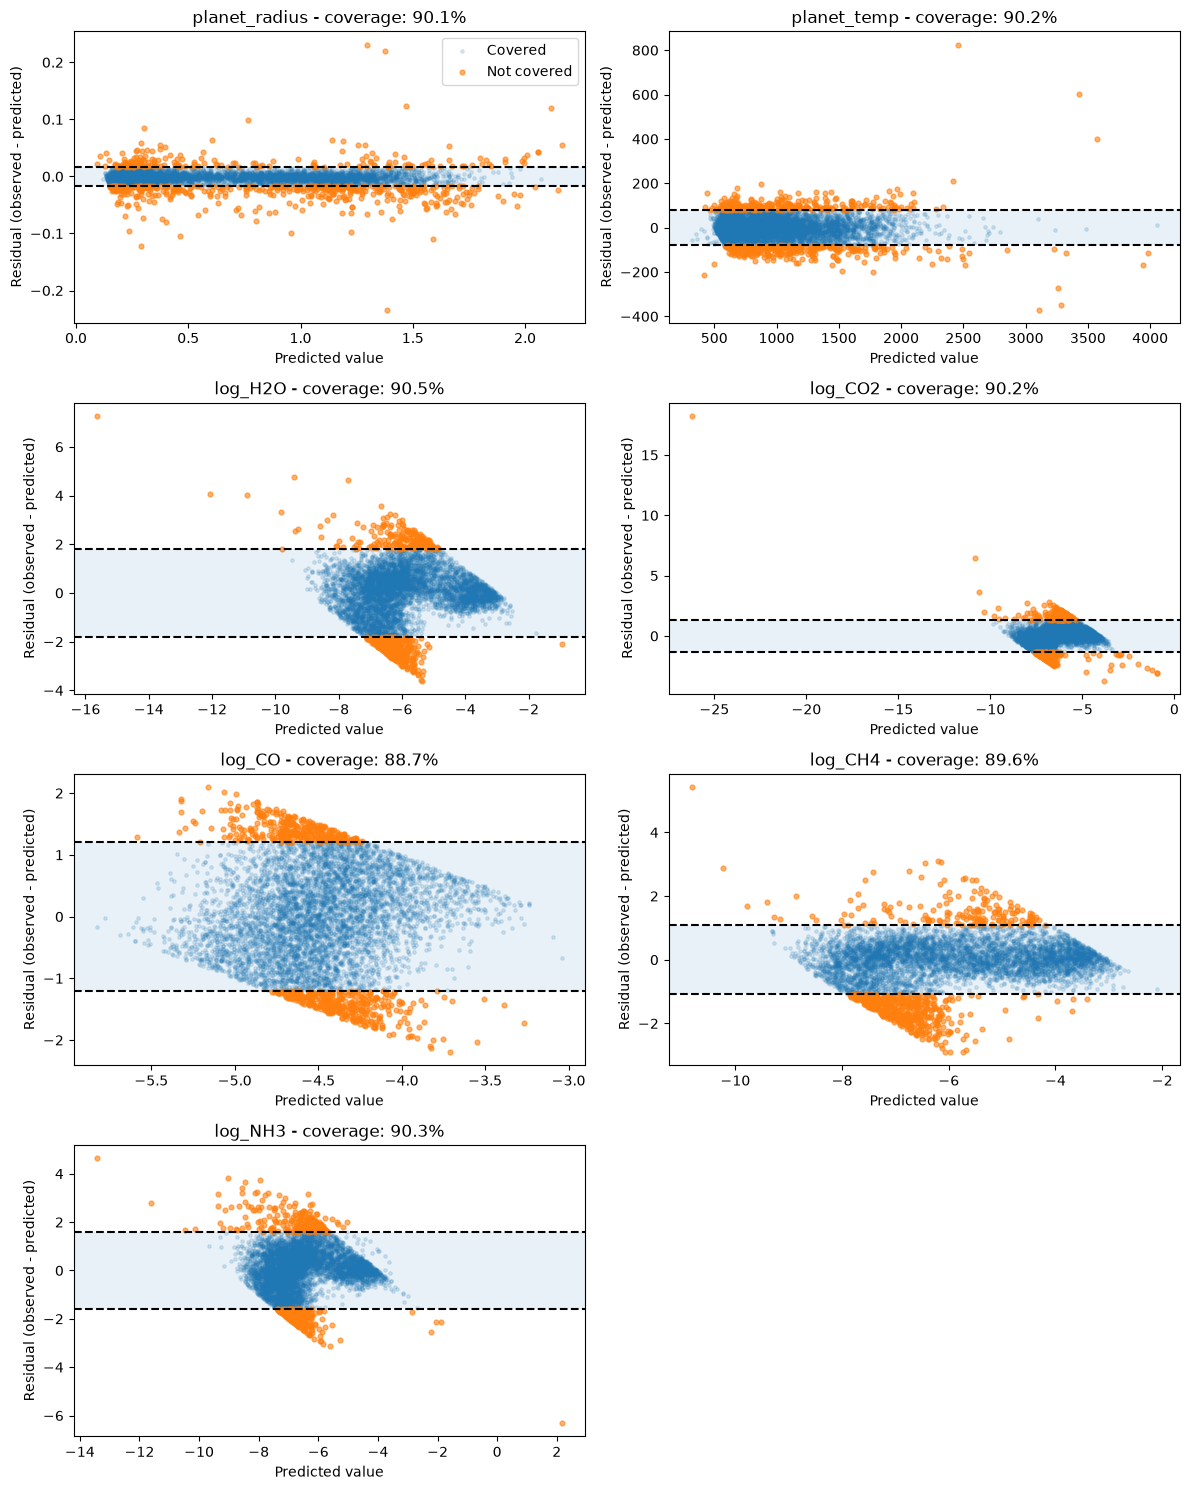

In [27]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(4, 2, figsize=(12, 15))

for ax, target in zip(axes.flat, TARGET_COLUMNS):
    predicted = test_predictions[target]
    residuals = y_internal_test[target] - predicted
    q = conformal_thresholds[target]

    covered = residuals.abs() <= q

    ax.scatter(
        predicted[covered],
        residuals[covered],
        s=6, alpha=0.15,
        label="Covered"
    )

    ax.scatter(
        predicted[~covered],
        residuals[~covered],
        s=12, alpha=0.6,
        label="Not covered"
    )

    ax.axhspan(-q, q, alpha=0.10)
    ax.axhline(q, color="black", linestyle="--")
    ax.axhline(-q, color="black", linestyle="--")

    ax.set_title(
        f"{target} - coverage: {covered.mean():.1%}"
    )
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual (observed - predicted)")

axes.flat[-1].axis("off")
axes.flat[0].legend()

plt.tight_layout()
plt.show()